<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS11_Praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

In [3]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

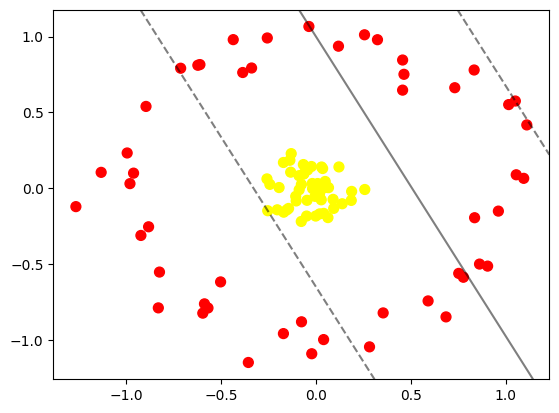

In [4]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

In [6]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# Menghitung r dengan fungsi radial basis (RBF) berpusat di tengah
r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-2.13601659e-02, -1.09108954e+00],
       [-1.36626109e-01,  1.84729889e-01],
       [-4.62216302e-02, -7.93385525e-02],
       [-6.10668814e-01,  8.15623926e-01],
       [ 1.11189060e+00,  4.17693859e-01],
       [-1.43442028e-01, -1.33047697e-01],
       [-1.52289151e-01, -1.42301797e-01],
       [-1.84942045e-02,  3.15603905e-02],
       [ 1.05626077e+00,  8.89405273e-02],
       [ 1.86820490e-01, -8.00280092e-02],
       [ 2.83098870e-01, -1.04580763e+00],
       [ 4.57404051e-01,  6.47063784e-01],
       [ 3.03800201e-02,  1.40250144e-01],
       [ 4.96015435e-02,  4.48361363e-02],
       [-1.05767414e-01, -5.32254345e-02],
       [ 7.32316162e-01,  6.63012481e-01],
       [ 9.62084713e-01, -1.50652197e-01],
       [ 1.01825332e-02,  3.12649474e-02],
       [-2.28131304e-03,  1.86044748e-02],
       [ 6.39235586e-02, -1.93324970e-01],
       [ 4.64548641e-01,  7.51458202e-01],
       [-2.42149357e-01,  2.57827430e-02],
       [-1.29627121e-01,  2.28497862e-01],
       [-8.84696273e-02,  8.28861220e-02],
       [-6.48019079e-02,  9.43421232e-02],
       [-3.63778383e-02,  1.06682655e+00],
       [ 9.05430976e-01, -5.13348969e-01],
       [ 9.42957583e-02, -1.32677544e-01],
       [ 3.60561339e-02,  1.30263419e-01],
       [-4.35096763e-01,  9.80075631e-01],
       [-7.12149672e-01,  7.91491407e-01],
       [-9.21672713e-01, -3.11092292e-01],
       [-4.12907873e-03, -5.31868722e-02],
       [ 8.62800871e-01, -4.99865880e-01],
       [-8.23781852e-01, -5.52566991e-01],
       [-6.31685535e-02,  9.51853040e-02],
       [ 2.86544044e-02, -7.61170880e-02],
       [ 2.02597653e-02, -1.68868641e-01],
       [-2.02931107e-01, -1.42051540e-01],
       [-5.68216980e-01, -7.89381006e-01],
       [-6.21596193e-01,  8.11092006e-01],
       [-8.94755878e-01,  5.39597774e-01],
       [-2.30845875e-02,  1.43467087e-01],
       [-6.54264019e-02,  1.56374058e-01],
       [-3.38387009e-01,  7.93048193e-01],
       [-8.81153285e-01, -2.54008255e-01],
       [ 1.88785227e-01, -2.07556877e-02],
       [ 5.91727477e-01, -7.42823648e-01],
       [ 9.09782203e-02, -7.32341790e-02],
       [ 1.39048431e-01, -1.02117284e-01],
       [ 4.18896714e-02,  1.38164872e-03],
       [-4.84937666e-02, -1.83175444e-01],
       [ 8.36805540e-01, -1.94231245e-01],
       [ 7.53205465e-01, -5.61298243e-01],
       [-4.40477784e-04, -1.83216454e-01],
       [-1.70632259e-01, -9.58319608e-01],
       [-9.94003281e-01,  2.32701441e-01],
       [-9.60329970e-01,  9.97144655e-02],
       [-1.70575563e-01,  1.69961575e-01],
       [ 6.86165539e-01, -8.48197963e-01],
       [ 5.29433172e-02,  1.65961119e-02],
       [-1.70143127e-02, -1.95382845e-03],
       [ 8.34431431e-01,  7.79848434e-01],
       [ 4.17804190e-02,  2.66591517e-02],
       [-7.65617315e-02, -2.18882916e-01],
       [-3.55515004e-01, -1.14875105e+00],
       [-1.93495516e-01,  4.81340181e-03],
       [-2.55660319e-01,  9.91068755e-01],
       [ 2.58157070e-01, -8.11320685e-03],
       [-9.79322225e-01,  3.05265229e-02],
       [ 3.24975770e-01,  9.79606360e-01],
       [ 4.17752261e-02, -1.65640708e-01],
       [-1.13108173e+00,  1.04923664e-01],
       [ 1.01643993e+00,  5.51773565e-01],
       [-4.34280589e-02,  1.20879698e-01],
       [-8.76225063e-02, -9.84926602e-03],
       [ 6.69423342e-02,  4.12288900e-03],
       [-2.57350335e-01,  6.18076382e-02],
       [-7.60412176e-02,  2.50608755e-02],
       [-1.26423470e+00, -1.21094084e-01],
       [ 1.09562911e+00,  6.54446185e-02],
       [ 4.11026095e-02, -9.97783605e-01],
       [-5.95524072e-01, -8.23498669e-01],
       [-5.01710138e-01, -6.17465888e-01],
       [-1.69145221e-01, -1.57719784e-01],
       [-5.86646661e-01, -7.62127452e-01],
       [ 3.54933217e-01, -8.21897027e-01],
       [-3.85072567e-01,  7.63316315e-01],
       [ 7.77642182e-01, -5.86749948e-01],
       [ 1.21950556e-01,  1.40626967e-01],
       [-8.29832460e-01, -7.88695003e-01],
       [ 4.57487643e-01,  8.45680455e-01

In [8]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

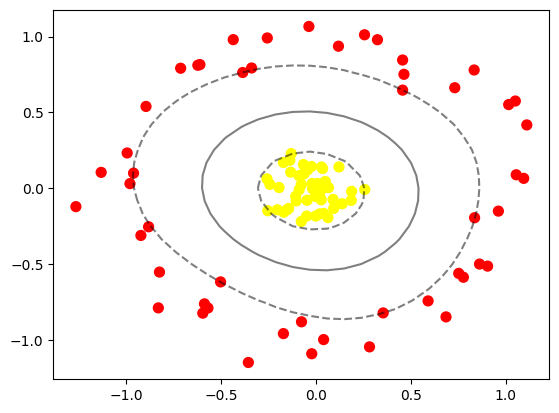

In [9]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')